# Logistic regression: will a player be booked at least once?
**Target:** `booked = 1` if the player has 1+ yellow or red card (`CrdY` + `CrdR` > 0), else 0.

**Features (per 90, no card data):** fouls committed, fouls drawn, tackles won, interceptions, offsides, crosses, plus age, minutes played (`90s`) and position flags. 

**Leakage guard:** `CrdY`, `CrdR`, `2CrdY`, and their `_stats_misc` duplicates are excluded. Goalkeepers are dropped.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
df = pd.read_csv('players_data-2026_2027.csv'); print(df.shape)

(2295, 102)


In [2]:
d = df[df['Pos'].notna() & ~df['Pos'].str.contains('GK')].copy()
d = d[d['90s'] >= 2].drop_duplicates(subset=['Player','Squad']).copy()
d['booked'] = ((d['CrdY'] + d['CrdR']) > 0).astype(int)
for k in ['Fls','Fld','TklW','Int','Off','Crs']: d[k+'_90'] = d[k] / d['90s']
d['DF'] = d['Pos'].str.startswith('DF').astype(int)
d['FW'] = d['Pos'].str.startswith('FW').astype(int)
feats = ['Fls_90','Fld_90','TklW_90','Int_90','Off_90','Crs_90','Age','90s','DF','FW']
d = d.dropna(subset=feats)
X, y = d[feats], d['booked']
print(len(d), 'players | booked rate:', round(y.mean(),3))

1495 players | booked rate: 0.628


In [3]:
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xtr,ytr)
pr = clf.predict_proba(Xte)[:,1]; pred = (pr>=0.5).astype(int)
print('Accuracy %.3f | AUC %.3f | baseline (always majority) %.3f' % (accuracy_score(yte,pred), roc_auc_score(yte,pr), max(yte.mean(),1-yte.mean())))
print(confusion_matrix(yte,pred)); print(classification_report(yte,pred))
cv = StratifiedKFold(5,shuffle=True,random_state=42)
print('5-fold AUC: %.3f' % cross_val_score(clf,X,y,cv=cv,scoring='roc_auc').mean())

Accuracy 0.662 | AUC 0.677 | baseline (always majority) 0.629
[[ 43  68]
 [ 33 155]]
              precision    recall  f1-score   support

           0       0.57      0.39      0.46       111
           1       0.70      0.82      0.75       188

    accuracy                           0.66       299
   macro avg       0.63      0.61      0.61       299
weighted avg       0.65      0.66      0.64       299

5-fold AUC: 0.728


,coef (per 1 SD),odds ratio
Off_90,-0.161,0.851
FW,-0.069,0.934
Crs_90,-0.058,0.944
Age,0.016,1.016
Fld_90,0.090,1.094
TklW_90,0.116,1.123
DF,0.159,1.173
Int_90,0.249,1.282
Fls_90,0.637,1.891
90s,0.678,1.969


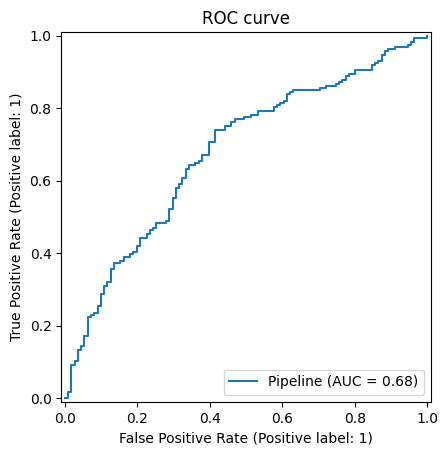

In [4]:
coef = pd.Series(clf[-1].coef_[0], feats)
odds = pd.DataFrame({'coef (per 1 SD)':coef, 'odds ratio':np.exp(coef)}).sort_values('coef (per 1 SD)')
display(odds.round(3))
RocCurveDisplay.from_estimator(clf,Xte,yte); plt.title('ROC curve'); plt.show()

In [5]:
d['p_booked'] = cross_val_predict(clf,X,y,cv=cv,method='predict_proba')[:,1]
cols = ['Player','Squad','Pos','90s','Fls_90','TklW_90','CrdY','CrdR','booked','p_booked']
print('Most likely to be booked but have NOT been (out-of-fold)')
display(d[d.booked==0].sort_values('p_booked',ascending=False)[cols].head(10).round(2))
print('Booked despite low predicted probability')
display(d[d.booked==1].sort_values('p_booked')[cols].head(10).round(2))

Most likely to be booked but have NOT been (out-of-fold)


,Player,Squad,Pos,90s,Fls_90,TklW_90,CrdY,CrdR,booked,p_booked
1448,Ilario Monterisi,Frosinone,DF,5.9,2.54,1.19,0,0,0,0.95
1052,Boubacar Kamara,Aston Villa,MF,8.8,2.16,1.82,0,0,0,0.94
692,Lewis Ferguson,Bologna,MF,10.0,2.20,1.20,0,0,0,0.94
169,Ezechiel Banzuzi,RB Leipzig,MF,6.7,2.69,1.94,0,0,0,0.94
702,Roberto Férnandez,Espanyol,FW,10.6,1.98,0.66,0,0,0,0.90
1724,Łukasz Poręba,Elversberg,MF,8.0,1.75,0.75,0,0,0,0.89
297,Gleison Bremer,Juventus,DF,10.0,1.20,0.70,0,0,0,0.89
1912,Martin Satriano,Getafe,"MF,FW",9.3,1.83,0.11,0,0,0,0.88
299,Lucas Bretelle,Le Mans,MF,6.5,1.69,1.69,0,0,0,0.88
1230,Danny Loader,Auxerre,"MF,FW",7.9,2.03,1.39,0,0,0,0.88


Booked despite low predicted probability


,Player,Squad,Pos,90s,Fls_90,TklW_90,CrdY,CrdR,booked,p_booked
1635,William Osula,Newcastle,FW,2.0,0.50,0.50,1,0,1,0.13
2211,Elye Wahi,Nice,FW,6.8,0.29,0.44,4,0,1,0.18
1786,Rodrigo Ribeiro,Augsburg,FW,2.3,1.30,0.43,2,0,1,0.18
801,Olivier Giroud,Lille,FW,4.7,0.43,0.43,1,0,1,0.20
1144,Andrej Kramarić,Hoffenheim,MF,2.2,0.45,0.00,1,0,1,0.20
133,Taiwo Awoniyi,Coventry City,FW,4.0,0.75,0.50,0,1,1,0.21
2133,Heorhii Tsitaishvili,Rayo Vallecano,MF,3.5,0.29,0.57,1,0,1,0.21
1270,Shuto Machino,Gladbach,FW,3.0,0.67,0.00,3,0,1,0.21
2137,Beñat Turrientes,Real Sociedad,MF,3.8,0.00,1.05,1,0,1,0.22
1309,Johan Manzambi,Aston Villa,MF,4.3,0.00,0.23,1,0,1,0.22


**Reading it:** odds ratios >1 raise the odds of a booking per one standard deviation increase in that feature. Minutes played will matter a lot: more time on the pitch means more chances to be booked. Early-season data, so many players are still at zero cards.

Likely bookings that haven't happened yet: Ilario Monterisi (0.95), Boubacar Kamara (0.94) and Lewis Ferguson (0.94). They commit many fouls and have no cards.